**Module 1 — Import libraries**

In [26]:

import os
import tarfile
import urllib.request
import random
import math

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.utils import save_image

# Check whether GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Set random seed
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)


Using device: cuda


**Module 2 — Download the dataset**

In [27]:

data_folder = "/content/pet_dataset"
os.makedirs(data_folder, exist_ok=True)

zip_path = data_folder + "/images.tar.gz"
image_folder = data_folder + "/images"

url = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz"

if not os.path.exists(zip_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, zip_path)

if not os.path.exists(image_folder):
    print("Extracting dataset...")
    with tarfile.open(zip_path, "r:gz") as file:
        file.extractall(data_folder)

image_paths = []

for file_name in os.listdir(image_folder):
    if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
        image_paths.append(image_folder + "/" + file_name)

image_paths.sort()

print("Total images:", len(image_paths))


Total images: 7390


**Module 3 — Display sample images**

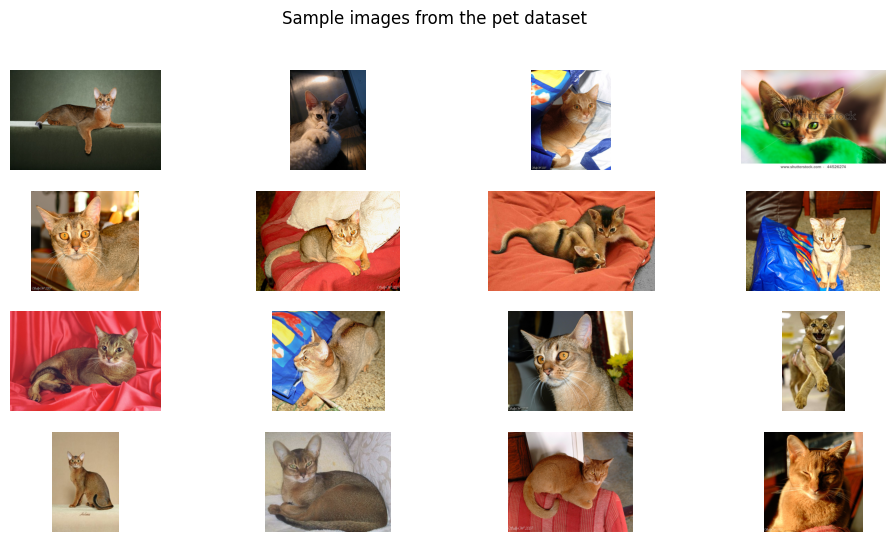

In [28]:

plt.figure(figsize=(12, 6))

for i in range(16):
    image = Image.open(image_paths[i]).convert("RGB")

    plt.subplot(4, 4, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.suptitle("Sample images from the pet dataset")
plt.show()

**Module 4 — Preprocessing and train-test split**

In [29]:

image_size = 64
batch_size = 32

image_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

class PetDataset(Dataset):
    def __init__(self, image_paths, transform):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(
            self.image_paths[index]
        ).convert("RGB")

        image = self.transform(image)
        return image


pet_dataset = PetDataset(image_paths, image_transform)

train_size = int(0.8 * len(pet_dataset))
test_size = len(pet_dataset) - train_size

train_dataset, test_dataset = random_split(
    pet_dataset,
    [train_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 5912
Testing images: 1478


**Module 5 — Create the noise schedule**

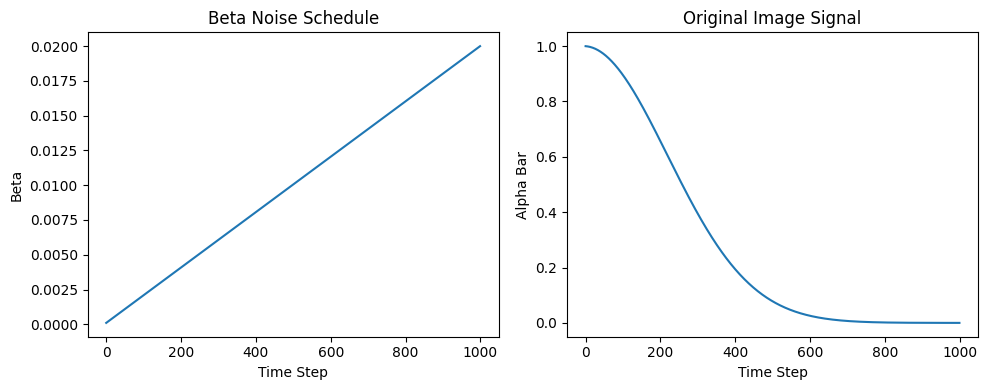

In [30]:

T = 1000

beta_start = 0.0001
beta_end = 0.02

betas = torch.linspace(
    beta_start, beta_end, T
).to(device)

alphas = 1 - betas

alpha_bars = torch.cumprod(
    alphas, dim=0
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(betas.cpu().numpy())
plt.title("Beta Noise Schedule")
plt.xlabel("Time Step")
plt.ylabel("Beta")

plt.subplot(1, 2, 2)
plt.plot(alpha_bars.cpu().numpy())
plt.title("Original Image Signal")
plt.xlabel("Time Step")
plt.ylabel("Alpha Bar")

plt.tight_layout()
plt.show()

**Module 6 — Forward diffusion**

In [31]:

def add_noise(images, time_steps):
    noise = torch.randn_like(images)

    alpha_bar_values = alpha_bars[time_steps]
    alpha_bar_values = alpha_bar_values.view(
        -1, 1, 1, 1
    )

    noisy_images = (
        torch.sqrt(alpha_bar_values) * images
        + torch.sqrt(1 - alpha_bar_values) * noise
    )

    return noisy_images, noise

**Module 7 — Visualize forward diffusion**

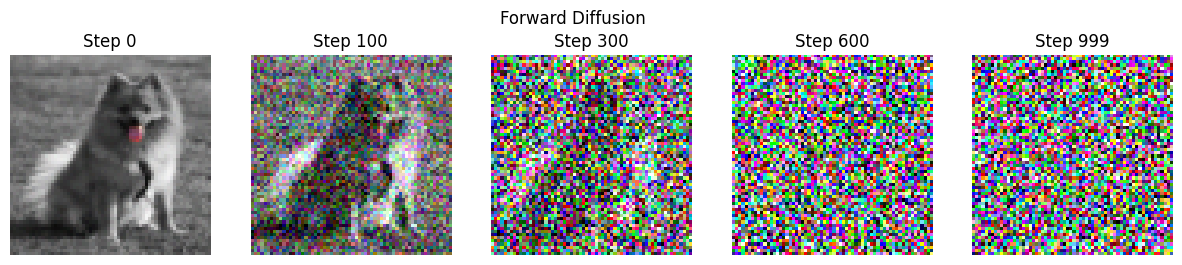

In [32]:

real_images = next(iter(test_loader)).to(device)
one_image = real_images[0:1]

steps_to_show = [0, 100, 300, 600, 999]

plt.figure(figsize=(15, 3))

for i, step in enumerate(steps_to_show):
    time_steps = torch.tensor(
        [step], device=device
    )

    noisy_image, noise = add_noise(
        one_image, time_steps
    )

    display_image = noisy_image[0].detach().cpu()
    display_image = (display_image + 1) / 2
    display_image = display_image.permute(1, 2, 0)
    display_image = display_image.clamp(0, 1)

    plt.subplot(1, 5, i + 1)
    plt.imshow(display_image)
    plt.title("Step " + str(step))
    plt.axis("off")

plt.suptitle("Forward Diffusion")
plt.show()


**Module 8 — Timestep embedding**

In [33]:

def time_embedding(time_steps, embedding_size):
    half_size = embedding_size // 2

    values = torch.arange(
        half_size, device=time_steps.device
    ).float()

    values = torch.exp(
        -math.log(10000)
        * values
        / max(half_size - 1, 1)
    )

    angles = (
        time_steps.float().unsqueeze(1)
        * values.unsqueeze(0)
    )

    embedding = torch.cat(
        [torch.sin(angles), torch.cos(angles)],
        dim=1
    )

    return embedding

**Module 9 — Build the U-Net**

In [34]:

class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.time_layer = nn.Sequential(
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 256)
        )

        self.first_conv = nn.Conv2d(
            3, 32, kernel_size=3, padding=1
        )

        self.down_conv1 = nn.Conv2d(
            32, 64, kernel_size=4,
            stride=2, padding=1
        )

        self.down_conv2 = nn.Conv2d(
            64, 128, kernel_size=4,
            stride=2, padding=1
        )

        self.middle_conv = nn.Conv2d(
            128, 128, kernel_size=3, padding=1
        )

        self.up_conv1 = nn.ConvTranspose2d(
            128, 64, kernel_size=4,
            stride=2, padding=1
        )

        self.up_conv2 = nn.ConvTranspose2d(
            128, 32, kernel_size=4,
            stride=2, padding=1
        )

        self.output_conv = nn.Conv2d(
            64, 3, kernel_size=3, padding=1
        )

        self.time_to_32 = nn.Linear(256, 32)
        self.time_to_64 = nn.Linear(256, 64)
        self.time_to_128 = nn.Linear(256, 128)

    def forward(self, image, time_steps):
        time = time_embedding(time_steps, 128)
        time = self.time_layer(time)

        first = F.relu(self.first_conv(image))
        first = first + self.time_to_32(
            time
        ).unsqueeze(2).unsqueeze(3)

        second = F.relu(self.down_conv1(first))
        second = second + self.time_to_64(
            time
        ).unsqueeze(2).unsqueeze(3)

        third = F.relu(self.down_conv2(second))
        third = third + self.time_to_128(
            time
        ).unsqueeze(2).unsqueeze(3)

        middle = F.relu(self.middle_conv(third))

        up1 = F.relu(self.up_conv1(middle))
        up1 = torch.cat([up1, second], dim=1)

        up2 = F.relu(self.up_conv2(up1))
        up2 = torch.cat([up2, first], dim=1)

        predicted_noise = self.output_conv(up2)

        return predicted_noise


model = UNet().to(device)

print(model)

UNet(
  (time_layer): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
  )
  (first_conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down_conv1): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (down_conv2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (middle_conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (up_conv1): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (up_conv2): ConvTranspose2d(128, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (output_conv): Conv2d(64, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_to_32): Linear(in_features=256, out_features=32, bias=True)
  (time_to_64): Linear(in_features=256, out_features=64, bias=True)
  (time_to_128): Linear(in_features=256, out_features=128, bias=True)
)


**Module 10 — Check the model**

In [35]:

sample_images = torch.randn(
    2, 3, image_size, image_size
).to(device)

sample_times = torch.randint(
    0, T, (2,), device=device
)

with torch.no_grad():
    predicted = model(sample_images, sample_times)

print("Input shape:", sample_images.shape)
print("Output shape:", predicted.shape)

Input shape: torch.Size([2, 3, 64, 64])
Output shape: torch.Size([2, 3, 64, 64])


**Module 11 — Train the model**

In [37]:

epochs = 40
learning_rate = 0.0002

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

loss_function = nn.MSELoss()

loss_values = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images in train_loader:
        images = images.to(device)

        current_batch_size = images.shape[0]

        time_steps = torch.randint(
            0, T, (current_batch_size,),
            device=device
        )

        noisy_images, actual_noise = add_noise(
            images, time_steps
        )

        predicted_noise = model(
            noisy_images, time_steps
        )

        loss = loss_function(
            predicted_noise, actual_noise
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    loss_values.append(average_loss)

    print(
        "Epoch", epoch + 1,
        "| Loss:", round(average_loss, 5)
    )

torch.save(
    model.state_dict(),
    "/content/ddpm_pet_model.pth"
)

print("Model saved successfully")

Epoch 1 | Loss: 0.07217
Epoch 2 | Loss: 0.06462
Epoch 3 | Loss: 0.06217
Epoch 4 | Loss: 0.06031
Epoch 5 | Loss: 0.05934
Epoch 6 | Loss: 0.05388
Epoch 7 | Loss: 0.0541
Epoch 8 | Loss: 0.05539
Epoch 9 | Loss: 0.05067
Epoch 10 | Loss: 0.04997
Epoch 11 | Loss: 0.04974
Epoch 12 | Loss: 0.05192
Epoch 13 | Loss: 0.04835
Epoch 14 | Loss: 0.04764
Epoch 15 | Loss: 0.04791
Epoch 16 | Loss: 0.04792
Epoch 17 | Loss: 0.04642
Epoch 18 | Loss: 0.04554
Epoch 19 | Loss: 0.04701
Epoch 20 | Loss: 0.0465
Epoch 21 | Loss: 0.04558
Epoch 22 | Loss: 0.04433
Epoch 23 | Loss: 0.04571
Epoch 24 | Loss: 0.04417
Epoch 25 | Loss: 0.04262
Epoch 26 | Loss: 0.04365
Epoch 27 | Loss: 0.04232
Epoch 28 | Loss: 0.04184
Epoch 29 | Loss: 0.04441
Epoch 30 | Loss: 0.04252
Epoch 31 | Loss: 0.04219
Epoch 32 | Loss: 0.04144
Epoch 33 | Loss: 0.04114
Epoch 34 | Loss: 0.04063
Epoch 35 | Loss: 0.03926
Epoch 36 | Loss: 0.04088
Epoch 37 | Loss: 0.04061
Epoch 38 | Loss: 0.04069
Epoch 39 | Loss: 0.03967
Epoch 40 | Loss: 0.03983
Model saved

**Module 12 — Plot training loss**

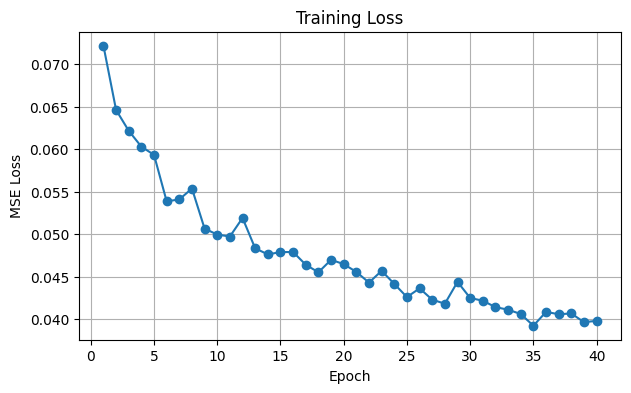

Initial loss: 0.07217270548681955
Final loss: 0.03982941957845076


In [38]:

plt.figure(figsize=(7, 4))

plt.plot(
    range(1, len(loss_values) + 1),
    loss_values,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

print("Initial loss:", loss_values[0])
print("Final loss:", loss_values[-1])

**Module 13 — Reverse diffusion and image generation**

In [39]:

# Previous cumulative alpha values
alpha_bars_previous = torch.cat([
    torch.tensor([1.0], device=device),
    alpha_bars[:-1]
])

@torch.no_grad()
def generate_images(number_of_images=8):
    model.eval()

    images = torch.randn(
        number_of_images, 3,
        image_size, image_size,
        device=device
    )

    saved_steps = {}

    for step in reversed(range(T)):
        time_steps = torch.full(
            (number_of_images,),
            step,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(images, time_steps)

        alpha = alphas[step]
        alpha_bar = alpha_bars[step]
        beta = betas[step]

        # Predict the previous, less noisy image
        predicted_mean = (
            images
            - (beta / torch.sqrt(1 - alpha_bar))
            * predicted_noise
        ) / torch.sqrt(alpha)

        # Add noise except at the final step
        if step > 0:
            previous_alpha_bar = alpha_bars_previous[step]

            variance = (
                beta * (1 - previous_alpha_bar)
                / (1 - alpha_bar)
            )

            images = predicted_mean + torch.sqrt(
                variance.clamp(min=1e-20)
            ) * torch.randn_like(images)
        else:
            images = predicted_mean

        if step in [999, 750, 500, 250, 100, 0]:
            saved_steps[step] = images.detach().cpu().clone()

    return images.clamp(-1, 1), saved_steps


generated_images, saved_steps = generate_images(8)
print("Generated image shape:", generated_images.shape)

Generated image shape: torch.Size([8, 3, 64, 64])


**Module 14 — Display generated images**

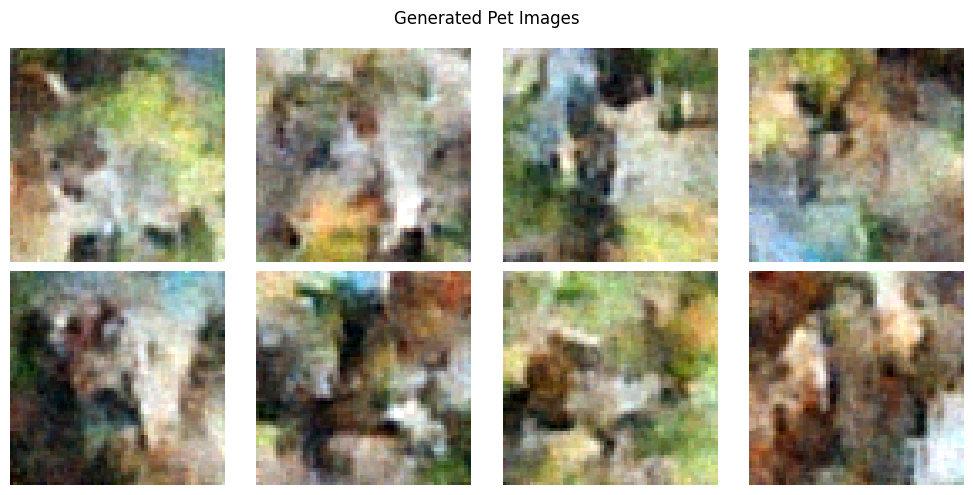

In [40]:
# Display generated images
plt.figure(figsize=(10, 5))

for i in range(len(generated_images)):
    image = (generated_images[i].cpu() + 1) / 2
    image = image.permute(1, 2, 0).clamp(0, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.suptitle("Generated Pet Images")
plt.tight_layout()
plt.show()

**Module 15 — Visualize intermediate denoising**

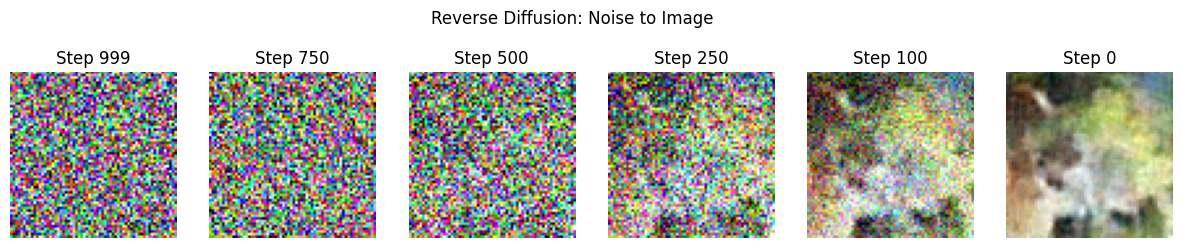

In [41]:

steps_to_show = [999, 750, 500, 250, 100, 0]

plt.figure(figsize=(15, 3))

for i, step in enumerate(steps_to_show):
    image = saved_steps[step][0]

    image = (image + 1) / 2
    image = image.permute(1, 2, 0).clamp(0, 1)

    plt.subplot(1, 6, i + 1)
    plt.imshow(image)
    plt.title("Step " + str(step))
    plt.axis("off")

plt.suptitle("Reverse Diffusion: Noise to Image")
plt.show()

**Module 16 — Compare real and generated images**

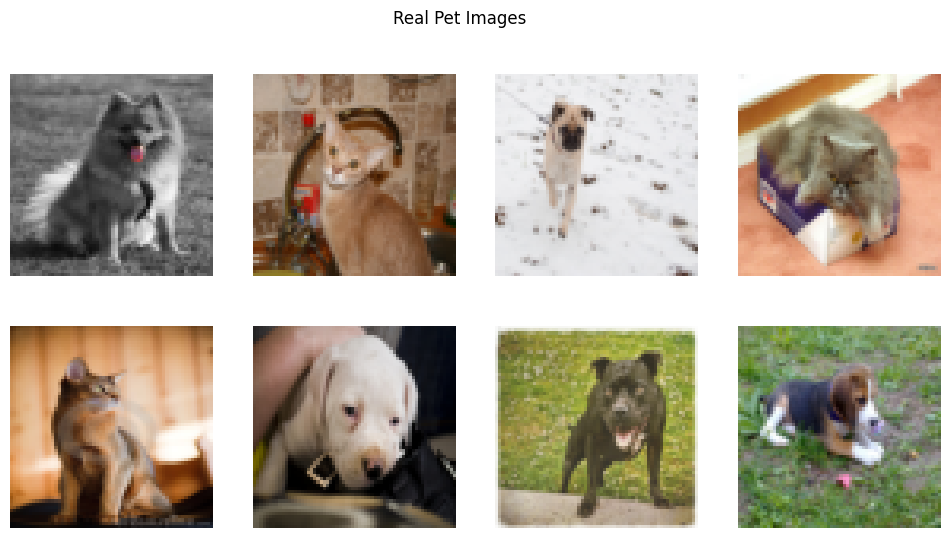

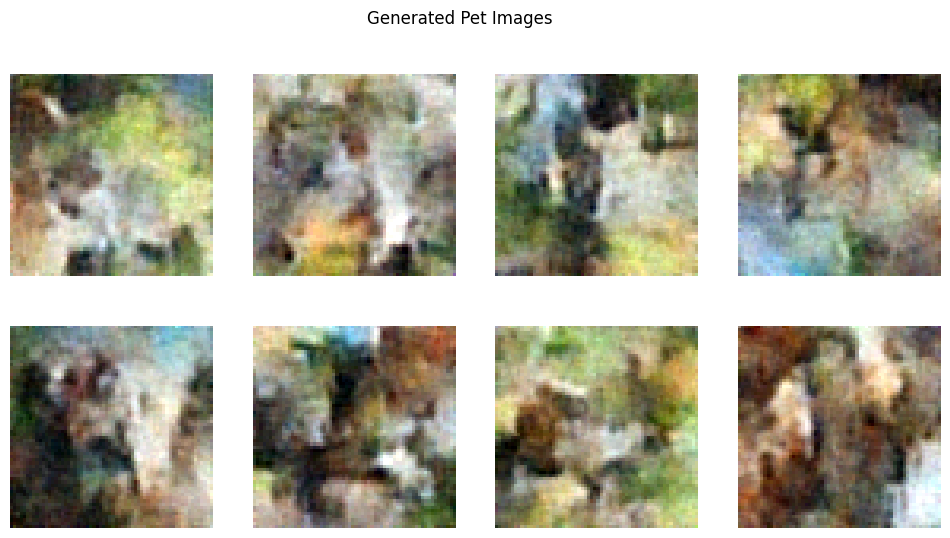

In [42]:

real_images = next(iter(test_loader))[:8]

plt.figure(figsize=(12, 6))

for i in range(8):
    image = (real_images[i] + 1) / 2
    image = image.permute(1, 2, 0).clamp(0, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.suptitle("Real Pet Images")
plt.show()


plt.figure(figsize=(12, 6))

for i in range(8):
    image = (generated_images[i].cpu() + 1) / 2
    image = image.permute(1, 2, 0).clamp(0, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.suptitle("Generated Pet Images")
plt.show()

Module 17 — Save generated images

In [47]:

output_folder = "/content/ddpm_pet_outputs"
os.makedirs(output_folder, exist_ok=True)

save_image(
    (generated_images.cpu() + 1) / 2,
    output_folder + "/generated_pet_images.png",
    nrow=4
)

print("Generated images saved in:", output_folder)
print("Model saved at: /content/ddpm_pet_model.pth")

Generated images saved in: /content/ddpm_pet_outputs
Model saved at: /content/ddpm_pet_model.pth
